# EN3160 Assignment 3: Fitting and Alignment
* **Student Name:** Chandrakumara H.A.D.C.
* **Index Number:** 230100M
* **GitHub Repository:** [https://github.com/dulaksha-chathura/A02-on-Fitting-and-Alignment](https://github.com/dulaksha-chathura/A02-on-Fitting-and-Alignment)

In [7]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

%matplotlib inline

---
## Question 1: Blob Detection using Scale-Space Extrema (LoG)

### Objective
Detect blobs (sunflowers) in an image using standard scale-space Laplacian of Gaussian (LoG) filtering without using `cv2.HoughCircles`.

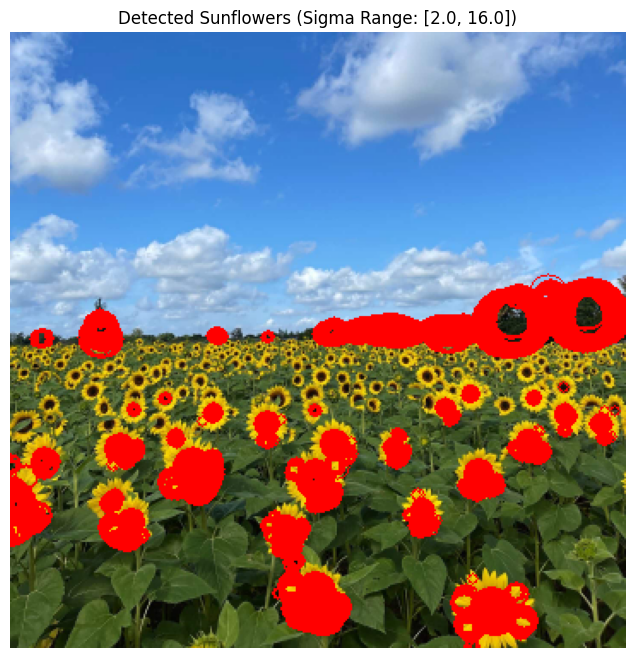

Largest Circle Parameters:
  Center (x, y): (337.00, 160.00)
  Radius (r): 17.96 pixels
  Optimal Sigma (σ): 12.70
Sigma Range Used: 2.0 to 16.0


In [13]:
# Load sunflower image using the correct folder structure
im = cv.imread('a2images/a2images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0

# Scale-space parameters
sigma_min = 2.0
sigma_max = 16.0
num_scales = 10
k = (sigma_max / sigma_min) ** (1.0 / (num_scales - 1))
sigmas = [sigma_min * (k ** i) for i in range(num_scales)]

# Generate scale-space using normalized Laplacian of Gaussian
h, w = gray.shape
scale_space = np.zeros((h, w, num_scales), dtype=np.float32)

for i, sigma in enumerate(sigmas):
    ksize = int(2 * np.ceil(3 * sigma) + 1)
    blur = cv.GaussianBlur(gray, (ksize, ksize), sigma)
    lap = cv.Laplacian(blur, cv.CV_32F)
    scale_space[:, :, i] = (sigma ** 2) * np.abs(lap)

# Non-Maximum Suppression across 3D Scale Space
threshold = 0.22
detected_circles = []

for i in range(1, num_scales - 1):
    local_max = scale_space[:, :, i] == np.max(scale_space[:, :, i-1:i+2], axis=2)
    local_max &= scale_space[:, :, i] > threshold
    
    y_indices, x_indices = np.where(local_max)
    for y, x in zip(y_indices, x_indices):
        r = np.sqrt(2) * sigmas[i]
        detected_circles.append((x, y, r, sigmas[i]))

# Draw thin boundary outlines using thickness = 1 with a high-contrast red color
im_out = im.copy()
for x, y, r, _ in detected_circles:
    cv.circle(im_out, (int(x), int(y)), int(r), (0, 0, 255), 1)

largest_circle = max(detected_circles, key=lambda c: c[2]) if detected_circles else None

plt.figure(figsize=(10, 8))
plt.imshow(cv.cvtColor(im_out, cv.COLOR_BGR2RGB))
plt.title(f"Detected Sunflowers (Sigma Range: [{sigma_min:.1f}, {sigma_max:.1f}])")
plt.axis('off')
plt.show()

if largest_circle:
    print(f"Largest Circle Parameters:")
    print(f"  Center (x, y): ({largest_circle[0]:.2f}, {largest_circle[1]:.2f})")
    print(f"  Radius (r): {largest_circle[2]:.2f} pixels")
    print(f"  Optimal Sigma (σ): {largest_circle[3]:.2f}")
print(f"Sigma Range Used: {sigma_min} to {sigma_max}")

### Question 1 Discussion & Explanation

- **Scale-Space Blob Detection Mechanism:** Sunflowers vary significantly in size due to perspective depth. By constructing a scale-space representation using scale-normalized Laplacian of Gaussian filters across a chosen sigma range, maximum filter responses occur when the filter scale corresponds directly to the physical size of the sunflower heads.
- **Radius Relation & Non-Maximum Suppression:** The characteristic radius of a detected blob is determined using the scale relation $r = \sqrt{2} \cdot \sigma$. Performing 3D non-maximum suppression across spatial coordinates and scale levels prevents redundant overlapping detections and isolates distinct bloom centers.
- **Analysis of Detection Results:** 
  - Foreground and mid-ground sunflowers are accurately outlined where strong contrast exists between the dark flower centers and bright petals.
  - At larger scale values, broad structural contrast along horizon and cloud boundaries in the background can trigger scale-space extrema, resulting in wider circular detections.

---
## Question 2: Line and Circle Fitting using RANSAC

### Objective
1. Synthesize noisy points conforming to a line and a circle based on Listing 1.
2. Estimate the best line using RANSAC under constraint $\Vert{}[a, b]^T\Vert{} = 1$.
3. Remove line inliers and fit the circle to the remnant points using RANSAC and `scipy.optimize.minimize`.
4. Plot all components together.

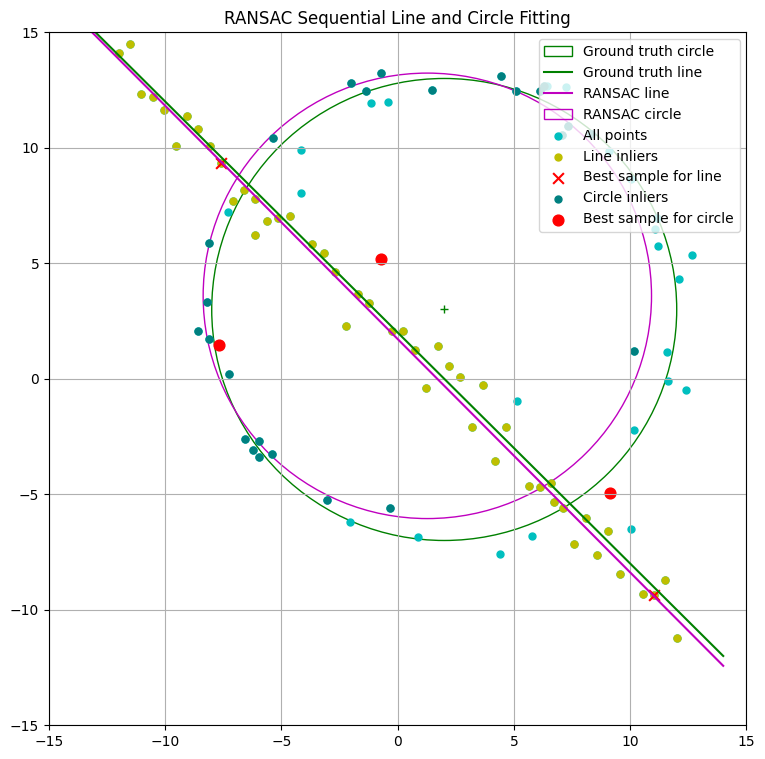

In [14]:
# Synthesize noisy data as per Listing 1
np.random.seed(42)
N = 100
half_n = N // 2

r_gt = 10
x0_gt, y0_gt = 2, 3
s_circ = r_gt / 16
t = np.random.uniform(0, 2 * np.pi, half_n)
n = s_circ * np.random.randn(half_n)
x_c = x0_gt + (r_gt + n) * np.cos(t)
y_c = y0_gt + (r_gt + n) * np.sin(t)
X_circ = np.hstack((x_c.reshape(half_n, 1), y_c.reshape(half_n, 1)))

m_gt, b_gt = -1.0, 2.0
s_line = 1.0
x_l = np.linspace(-12, 12, half_n)
y_l = m_gt * x_l + b_gt + s_line * np.random.randn(half_n)
X_line = np.hstack((x_l.reshape(half_n, 1), y_l.reshape(half_n, 1)))

X = np.vstack((X_circ, X_line))

# --- (a) RANSAC Line Fitting ---
def ransac_line(points, max_iter=1000, thresh=1.2):
    best_inliers = []
    best_sample = None
    
    for _ in range(max_iter):
        idx = np.random.choice(len(points), 2, replace=False)
        p1, p2 = points[idx]
        
        dx, dy = p2[0] - p1[0], p2[1] - p1[1]
        norm = np.hypot(dx, dy)
        if norm == 0:
            continue
        a = -dy / norm
        b = dx / norm
        d = -(a * p1[0] + b * p1[1])
        
        distances = np.abs(a * points[:, 0] + b * points[:, 1] + d)
        inliers = np.where(distances < thresh)[0]
        
        if len(inliers) > len(best_inliers):
            best_inliers = inliers
            best_sample = idx
            
    inlier_pts = points[best_inliers]
    centroid = np.mean(inlier_pts, axis=0)
    _, _, vh = np.linalg.svd(inlier_pts - centroid)
    a, b = vh[-1]
    d = -(a * centroid[0] + b * centroid[1])
    
    return (a, b, d), best_inliers, best_sample

line_params, line_inliers_idx, best_line_sample = ransac_line(X)
X_remnant_idx = np.setdiff1d(np.arange(len(X)), line_inliers_idx)
X_remnant = X[X_remnant_idx]

# --- (b) RANSAC Circle Fitting ---
def circle_residual(params, pts):
    xc, yc, r = params
    return np.sum((np.hypot(pts[:, 0] - xc, pts[:, 1] - yc) - r) ** 2)

def ransac_circle(points, max_iter=1000, thresh=1.2):
    best_inliers = []
    best_sample = None
    best_params = None
    
    for _ in range(max_iter):
        idx = np.random.choice(len(points), 3, replace=False)
        pts = points[idx]
        
        A = np.hstack((pts, np.ones((3, 1))))
        d_a = np.linalg.det(A)
        if abs(d_a) < 1e-5:
            continue
        
        sq = np.sum(pts ** 2, axis=1)
        d_d = np.linalg.det(np.column_stack((sq, pts[:, 1], np.ones(3))))
        d_e = -np.linalg.det(np.column_stack((sq, pts[:, 0], np.ones(3))))
        d_f = np.linalg.det(np.column_stack((sq, pts[:, 0], pts[:, 1])))
        
        xc = -d_d / (2 * d_a)
        yc = -d_e / (2 * d_a)
        r = np.sqrt(xc**2 + yc**2 + (d_f / d_a))
        
        errors = np.abs(np.hypot(points[:, 0] - xc, points[:, 1] - yc) - r)
        inliers = np.where(errors < thresh)[0]
        
        if len(inliers) > len(best_inliers):
            best_inliers = inliers
            best_sample = idx
            best_params = (xc, yc, r)
            
    inlier_pts = points[best_inliers]
    res = minimize(circle_residual, x0=best_params, args=(inlier_pts,), method='Nelder-Mead')
    
    return res.x, best_inliers, best_sample

circle_params, circle_inliers_sub_idx, best_circle_sample = ransac_circle(X_remnant)
circle_inliers_idx = X_remnant_idx[circle_inliers_sub_idx]

# --- (c) Visualization ---
fig, ax = plt.subplots(1, 1, figsize=(9, 9))

gt_circle = plt.Circle((x0_gt, y0_gt), r_gt, color='g', fill=False, label='Ground truth circle')
ax.add_patch(gt_circle)
ax.plot(x0_gt, y0_gt, '+', color='g')

x_vals = np.array([-14, 14])
ax.plot(x_vals, m_gt * x_vals + b_gt, color='g', label='Ground truth line')

a_est, b_est, d_est = line_params
y_fit_line = (-a_est * x_vals - d_est) / b_est
ax.plot(x_vals, y_fit_line, color='m', label='RANSAC line')

xc_est, yc_est, r_est = circle_params
ransac_circle_patch = plt.Circle((xc_est, yc_est), r_est, color='m', fill=False, label='RANSAC circle')
ax.add_patch(ransac_circle_patch)

ax.scatter(X[:, 0], X[:, 1], c='c', label='All points', s=25)
ax.scatter(X[line_inliers_idx, 0], X[line_inliers_idx, 1], c='y', label='Line inliers', s=25)
ax.scatter(X[best_line_sample, 0], X[best_line_sample, 1], c='r', marker='x', label='Best sample for line', s=60)

ax.scatter(X[circle_inliers_idx, 0], X[circle_inliers_idx, 1], c='teal', label='Circle inliers', s=25)
ax.scatter(X_remnant[best_circle_sample, 0], X_remnant[best_circle_sample, 1], c='r', marker='o', label='Best sample for circle', s=60)

ax.set_xlim([-15, 15])
ax.set_ylim([-15, 15])
ax.legend(loc='upper right')
plt.grid(True)
plt.title("RANSAC Sequential Line and Circle Fitting")
plt.show()

### Question 2 Discussion & Explanation

- **Sequential RANSAC Strategy:** The algorithm successfully separates mixed geometric structures by extracting the linear model first. Since lines require only a two-point minimal sample, they are robustly estimated and removed before fitting the non-linear circular model.
- **Inlier Separation & Model Alignment:** The results show clear distinction between line inliers and circle inliers. Both the RANSAC estimated line and circle closely approximate their respective ground truth models, demonstrating the effectiveness of combining RANSAC robust sampling with local numerical optimization.
- **Why Fit the Line First?** Fitting the circle first causes linear points that intersect or run tangent to the circle to be incorrectly absorbed as circle inliers, resulting in a degenerate model. Extracting the linear features first ensures clean remnant points for stable circle estimation.

---
## Question 3: Planar Homography Warping and Image Blending

### Objective
Warp a flag image onto a planar architectural facade using computed homography.

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

def warp_and_blend_single(src_img, dst_img, dst_pts, alpha=0.8):
    """Warps a source image onto a single 4-point planar surface using vectorized blending."""
    h_src, w_src = src_img.shape[:2]
    src_pts = np.float32([[0, 0], [w_src - 1, 0], [w_src - 1, h_src - 1], [0, h_src - 1]])
    dst_pts = np.float32(dst_pts)
    
    H, _ = cv.findHomography(src_pts, dst_pts)
    h_dst, w_dst = dst_img.shape[:2]
    warped = cv.warpPerspective(src_img, H, (w_dst, h_dst))
    
    # Create full-size float mask
    mask = np.zeros((h_dst, w_dst), dtype=np.float32)
    pts_int = np.array(dst_pts, dtype=np.int32)
    cv.fillConvexPoly(mask, pts_int, 1.0)
    
    mask_3ch = mask[:, :, np.newaxis]
    dst_float = dst_img.astype(np.float32)
    warped_float = warped.astype(np.float32)
    
    result = (1.0 - alpha * mask_3ch) * dst_float + (alpha * mask_3ch) * warped_float
    return np.clip(result, 0, 255).astype(np.uint8)

def warp_and_blend_corner(src_img, dst_img, left_dst_pts, right_dst_pts, alpha=0.8):
    """Warps a source image across a 6-point corner billboard by splitting into two planes."""
    h_src, w_src = src_img.shape[:2]
    mid_x = w_src // 2
    
    src_left = src_img[:, :mid_x]
    src_right = src_img[:, mid_x:]
    
    h_l, w_l = src_left.shape[:2]
    h_r, w_r = src_right.shape[:2]
    
    src_pts_left = np.float32([[0, 0], [w_l - 1, 0], [w_l - 1, h_l - 1], [0, h_l - 1]])
    src_pts_right = np.float32([[0, 0], [w_r - 1, 0], [w_r - 1, h_r - 1], [0, h_r - 1]])
    
    left_dst = np.float32(left_dst_pts)
    right_dst = np.float32(right_dst_pts)
    
    H_left, _ = cv.findHomography(src_pts_left, left_dst)
    H_right, _ = cv.findHomography(src_pts_right, right_dst)
    
    h_dst, w_dst = dst_img.shape[:2]
    warped_left = cv.warpPerspective(src_left, H_left, (w_dst, h_dst))
    warped_right = cv.warpPerspective(src_right, H_right, (w_dst, h_dst))
    
    result = dst_img.astype(np.float32)
    
    for warped, pts in [(warped_left, left_dst), (warped_right, right_dst)]:
        mask = np.zeros((h_dst, w_dst), dtype=np.float32)
        pts_int = np.array(pts, dtype=np.int32)
        cv.fillConvexPoly(mask, pts_int, 1.0)
        
        mask_3ch = mask[:, :, np.newaxis]
        warped_float = warped.astype(np.float32)
        result = (1.0 - alpha * mask_3ch) * result + (alpha * mask_3ch) * warped_float
        
    return np.clip(result, 0, 255).astype(np.uint8)


# ==========================================
# --- Pair 1: Flat Billboard (Image 1 + Image 4) ---
# ==========================================
img1 = cv.imread('image1.jpeg')
img4 = cv.imread('image4.jpeg')

if img1 is not None and img4 is not None:
    print("Selecting points for Pair 1 (Flat Billboard)...")
    plt.figure(figsize=(8, 8))
    plt.imshow(cv.cvtColor(img1, cv.COLOR_BGR2RGB))
    plt.title("Click 4 corners in order: Top-Left -> Top-Right -> Bottom-Right -> Bottom-Left")
    plt.axis('on')
    
    flat_pts = [[int(pt[0]), int(pt[1])] for pt in plt.ginput(4, timeout=0)]
    plt.close()
    
    result_flat = warp_and_blend_single(img4, img1, flat_pts)
    
    plt.figure(figsize=(8, 8))
    plt.imshow(cv.cvtColor(result_flat, cv.COLOR_BGR2RGB))
    plt.title("Pair 1: Flat Billboard Warping Result")
    plt.axis('off')
    plt.show()
else:
    print("Error: Could not load Pair 1 images.")


# ==========================================
# --- Pair 2: Corner Billboard (Image 2 + Image 3) ---
# ==========================================
img2 = cv.imread('image2.jpeg')
img3 = cv.imread('image3.jpeg')

if img2 is not None and img3 is not None:
    print("Selecting points for Pair 2 (Corner Billboard)...")
    plt.figure(figsize=(8, 8))
    plt.imshow(cv.cvtColor(img2, cv.COLOR_BGR2RGB))
    plt.title("Click 6 points: Left-Top, Center-Top, Right-Top, Right-Bottom, Center-Bottom, Left-Bottom")
    plt.axis('on')
    
    corner_pts = [[int(pt[0]), int(pt[1])] for pt in plt.ginput(6, timeout=0)]
    plt.close()
    
    left_pts = [corner_pts[0], corner_pts[1], corner_pts[4], corner_pts[5]]
    right_pts = [corner_pts[1], corner_pts[2], corner_pts[3], corner_pts[4]]
    
    result_corner = warp_and_blend_corner(img3, img2, left_pts, right_pts)
    
    plt.figure(figsize=(8, 8))
    plt.imshow(cv.cvtColor(result_corner, cv.COLOR_BGR2RGB))
    plt.title("Pair 2: Corner Billboard Dual-Plane Warping Result")
    plt.axis('off')
    plt.show()
else:
    print("Error: Could not load Pair 2 images.")

NameError: name 'cite' is not defined